# Data analysis
## Bissal Youssef - Lombardozzi Christian
### IUM project 2024/25

In [11]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.colors import ListedColormap

df_releases = pd.read_csv('../data/releases.csv')
df_genres = pd.read_csv('../data/genres.csv')
df_movies = pd.read_csv('../data/movies.csv')
df_studios = pd.read_csv('../data/studios.csv')
df_themes = pd.read_csv('../data/themes.csv')
df_countries = gpd.read_file('../data/countries.csv')
df_languages = pd.read_csv('../data/languages.csv')
df_posters = pd.read_csv('../data/posters.csv')
df_reviews = pd.read_csv('../data/rotten_tomatoes_reviews.csv')
df_crew = pd.read_csv('../data/crew.csv')
df_posters = pd.read_csv('../data/posters.csv')
df_oscars = pd.read_csv('../data/the_oscar_awards.csv')
df_releases = pd.read_csv('../data/releases.csv')
df_actors = pd.read_csv('../data/actors.csv')


In [5]:
df_actors['name'].duplicated()

0          False
1          False
2          False
3          False
4          False
           ...  
5798445     True
5798446    False
5798447     True
5798448     True
5798449     True
Name: name, Length: 5798450, dtype: bool

* Is there any currelation between the rating of a movie and the number of oscars won by its actors after the release?

<Axes: xlabel='oscars_won', ylabel='rating'>

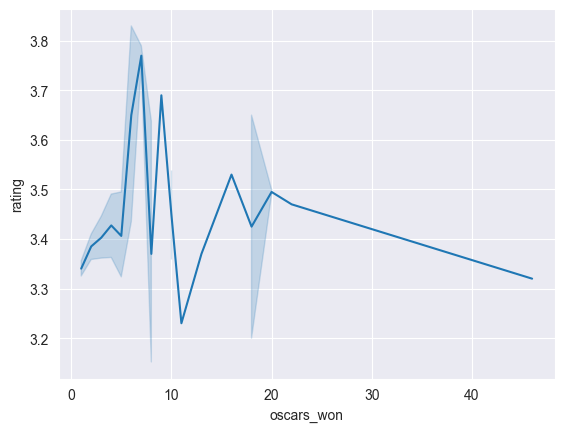

In [29]:
#da completare

df_actors['name'] = df_actors['name'].astype(str)
df_oscars['name'] = df_oscars['name'].astype(str)

df_actors_oscar = df_oscars[(df_oscars['winner'] == True) &
                            (df_oscars['category'].isin(["ACTOR", "ACTRESS"]))]


df_actors_oscar = df_actors_oscar.merge(df_actors, on='name', how='inner')

df_actors_oscar = df_actors_oscar.merge(df_movies, on='id', how='inner')

df_actors_oscar = df_actors_oscar[df_actors_oscar['year_film'] <= df_actors_oscar['year_ceremony']]

df_actors_oscar_per_movie = df_actors_oscar.groupby('id').agg({'winner': 'count'}).reset_index()

df_actors_oscar_per_movie.columns = ['id', 'oscars_won']

df_actors_oscar_per_movie = df_actors_oscar_per_movie.merge(df_movies, on='id', how='inner')

df_actors_oscar_per_movie = df_actors_oscar_per_movie[['id', 'rating', 'oscars_won']]

sns.lineplot(data=df_actors_oscar_per_movie, x='oscars_won', y='rating')

* Are the countries which produce more film translate a lot of films as well?

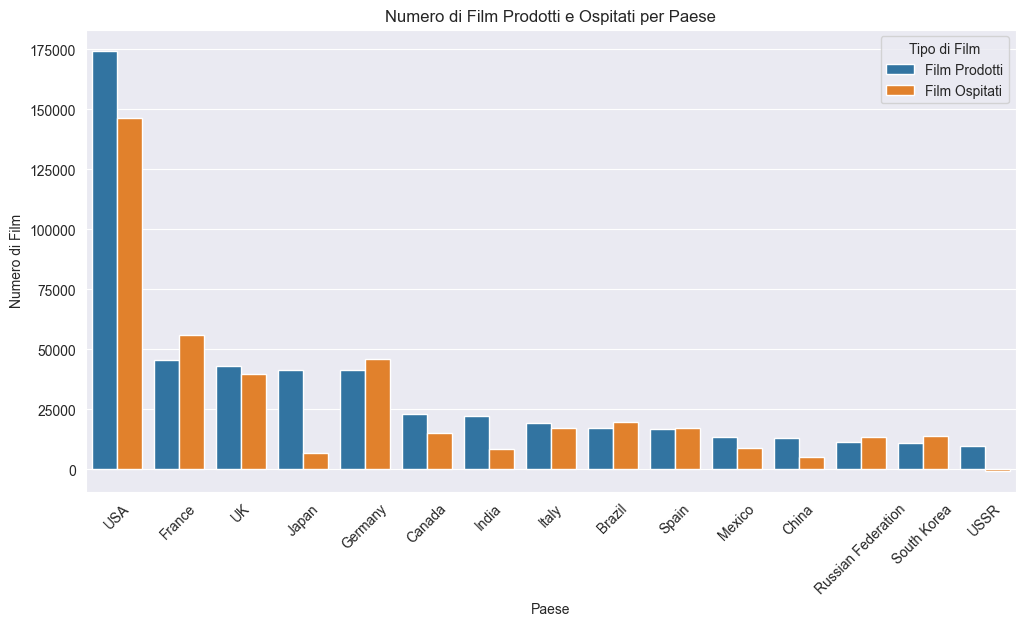

In [89]:

produced_films_per_country = df_countries['country'].value_counts().reset_index(name='produced_films')
produced_films_per_country.columns = ['country', 'produced_films']


hosted_films_per_country = df_releases['country'].value_counts().reset_index(name='hosted_films')
hosted_films_per_country.columns = ['country', 'hosted_films']

combined = pd.merge(produced_films_per_country, hosted_films_per_country, on='country', how='outer').fillna(0)

# Calcola i film ospitati esclusivamente (ossia film ospitati meno quelli prodotti)
combined['hosted_exclusively'] = combined['hosted_films'] - combined['produced_films']


top_countries = combined.nlargest(15, 'produced_films')


combined_melted = top_countries.melt(id_vars='country', value_vars=['produced_films', 'hosted_exclusively'],
                                     var_name='film_type', value_name='count')


combined_melted['film_type'] = combined_melted['film_type'].map({
    'produced_films': 'Film Prodotti',
    'hosted_exclusively': 'Film Ospitati'
})


plt.figure(figsize=(12, 6))
sns.barplot(data=combined_melted, x='country', y='count', hue='film_type')
plt.xlabel('Paese')
plt.ylabel('Numero di Film')
plt.title('Numero di Film Prodotti e Ospitati per Paese')
plt.xticks(rotation=45)
plt.legend(title='Tipo di Film')
plt.show()


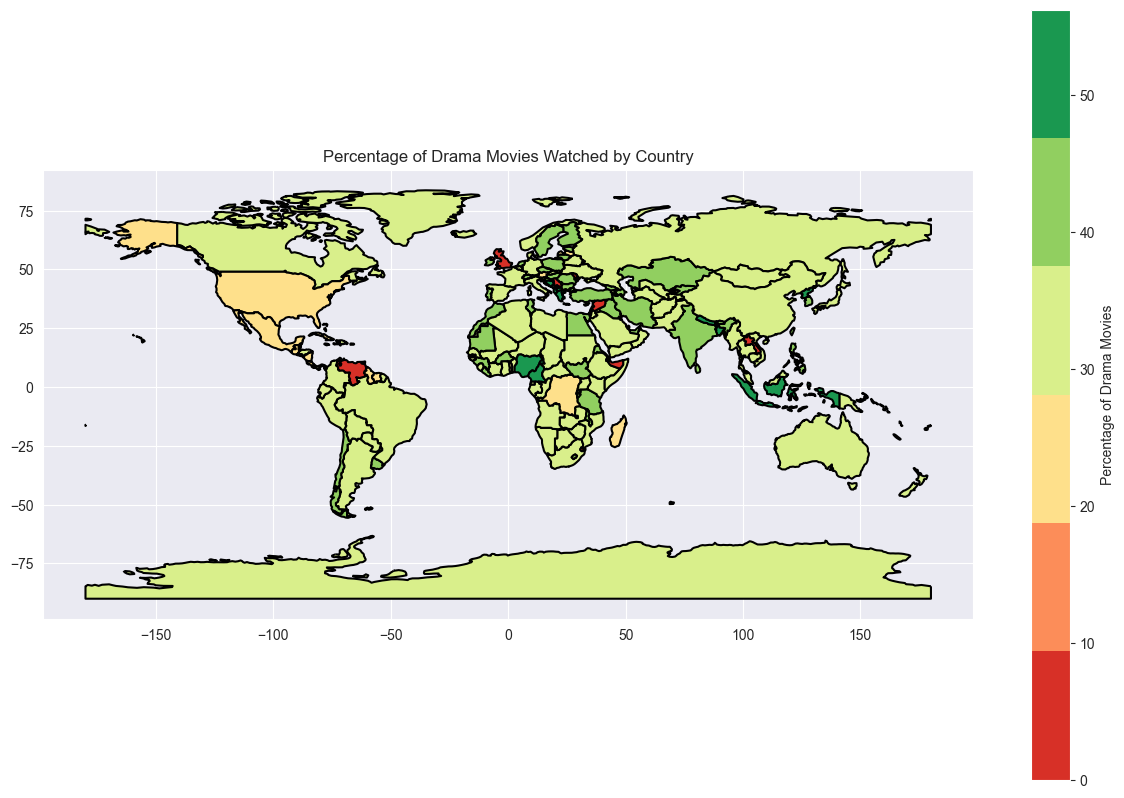

In [102]:

drama_movies = df_genres[df_genres['genre'] == 'Drama']


df_releases['country'] = df_releases['country'].replace({
    'US': 'United States of America',
    'USA': 'United States of America',
    'United States': 'United States of America',
    'Uk': 'United Kingdom',
    'Russian Federation': 'Russia',
    'Congo': 'Republic of the Congo',
    'Democratic Republic of Congo': 'Democratic Republic of the Congo',
})

df_countries['country'] = df_countries['country'].replace({
    'US': 'United States of America',
    'USA': 'United States of America',
    'United States': 'United States of America',
    'Uk': 'United Kingdom',
    'Russian Federation': 'Russia',
    'Congo': 'Republic of the Congo',
    'Democratic Republic of Congo': 'Democratic Republic of the Congo',
})

total_movies_per_country = df_releases['country'].value_counts().reset_index(name='total_movies_count')

drama_movies_per_country = df_releases.merge(drama_movies, on='id', how='inner')
drama_movies_per_country = drama_movies_per_country['country'].value_counts().reset_index(name='drama_movies_count')


combined = pd.merge(drama_movies_per_country, total_movies_per_country, on='country', how='inner')
combined.columns = ['country', 'drama_movies_count', 'total_movies_count']

# Calculate the percentage of drama movies
combined['drama_percentage'] = (combined['drama_movies_count'] / combined['total_movies_count']) * 100


world = gpd.read_file('https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip')


world_data_gdf = world.merge(combined, how='left', left_on='SOVEREIGNT', right_on='country')


world_data_gdf['drama_percentage'] = world_data_gdf['drama_percentage'].fillna(0)

colors = ['#d73027', '#fc8d59', '#fee08b', '#d9ef8b', '#91cf60', '#1a9850']
cmap = ListedColormap(colors)


world_data_gdf.plot(figsize=(15, 10), edgecolor='black', linewidth=1.5, column='drama_percentage', legend=True,
                   cmap=cmap,  legend_kwds={'label': "Percentage of Drama Movies"})
plt.title('Percentage of Drama Movies Watched by Country')
plt.show()